**Gaussians → mesh → mesh + fewer Gaussians.** Starting from randomly initialized Gaussians and images only, this pipeline ends with a hybrid model (a mesh plus a quarter of the Gaussians) that renders better than the Gaussians it started from, with fewer parameters.

**Ground truth.** The detailed textured Spot mesh, lit by a point light, pre-rendered (color and silhouette) from 24 orbit views (training) and 6 other views (testing). No ground-truth geometry is used for training.

1. **Gaussians**: N Gaussians, randomly initialized in a box around the scene, trained on the images (plain 3DGS).
2. **Mesh extraction**: depth and silhouette of the trained Gaussians, rendered from 60 views, are fused into a truncated signed distance volume; marching cubes gives a mesh (largest connected component), with vertex colors from the nearest Gaussians.
3. **Mesh**: its vertices (large steps parameterization) and vertex colors are trained on the images.
4. **Hybrid**: N / 4 Gaussians are added just in front of the mesh surface (flat, with the mesh's lit colors, mostly transparent), and the mesh and the Gaussians are trained together through Gmesh.

**Baselines**: the stage 1 Gaussians trained further (as many more iterations as stages 3 + 4), and N / 4 Gaussians alone.

Needs scikit-image (marching cubes): `pip install scikit-image`. The helpers are shared with the script version, `examples/train_gs2mesh_toy.py`.

In [1]:
## Computing Device
device = 'cuda:0'
import torch
torch.cuda.set_device(device)

import os, sys
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

sys.path.insert(0, os.path.abspath('..'))  # the repository root (this notebook runs from ./examples)
sys.path.insert(0, os.path.abspath('.'))   # ./examples, for train_gs2mesh_toy.py

from gmesh.scenes.mesh import Mesh
from gmesh.scenes.cameras import OrbitCamera
from train_textured_toy import load_scene, orbit_poses, make_gaussians
from train_hybrid_toy import make_renderers, chamfer_distance
from train_gs2mesh_toy import (random_gaussian_params, train_gaussians, extraction_poses, extract_mesh,
                               colors_from_gaussians, initial_mesh, mesh_verts, make_mesh, train_mesh,
                               train_hybrid, count)

torch.manual_seed(0)

### Ground truth

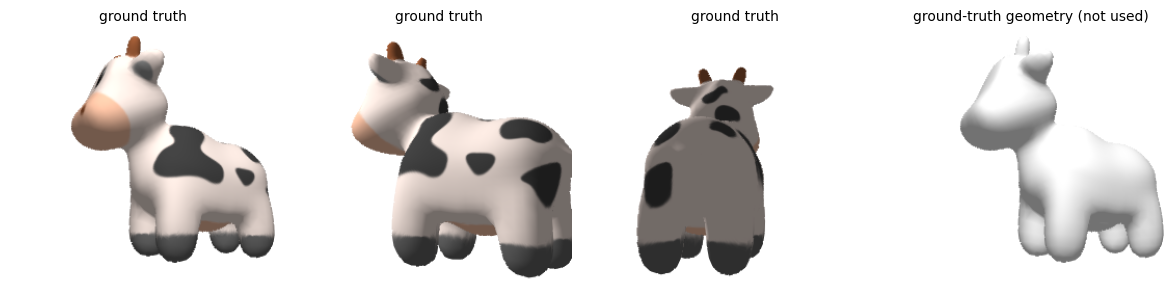

In [2]:
IMAGE_SIZE = 256
N = 20000             # Gaussians of stage 1 (stage 4 adds N / 4)
GAUSSIAN_ITERS = 3000
MESH_ITERS = 1500
HYBRID_ITERS = 2000

gt_mesh, light = load_scene(device)
camera = OrbitCamera(image_width=IMAGE_SIZE, image_height=IMAGE_SIZE, fov_x=40, fov_y=40,
                     z_near=0.1, z_far=100, device=device)
renderers = make_renderers(camera, light)   # MeshRenderer, GaussianRasterizer, GmeshRenderer (same light)
mesh_renderer, gaussian_rasterizer, gmesh_renderer = renderers
train_poses, test_poses = orbit_poses(device)
with torch.no_grad():   # (rgb, alpha) of each view
    gt_train = [(r[0], a[0]) for r, _, a in (mesh_renderer.render(gt_mesh, p) for p in train_poses)]
    gt_test = [(r[0], a[0]) for r, _, a in (mesh_renderer.render(gt_mesh, p) for p in test_poses)]

def to_np(img):
    return img.detach().clamp(0, 1).cpu().numpy()

def show_images(images, titles, size=3.0):
    fig, axs = plt.subplots(1, len(images), figsize=(size * len(images), size))
    for ax, img, title in zip(np.atleast_1d(axs), images, titles):
        ax.imshow(to_np(img))
        ax.set_title(title, fontsize=10)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

def geometry(verts, faces, pose):
    """the mesh shape only: white vertex colors, lit"""
    with torch.no_grad():
        return mesh_renderer.render(Mesh(verts=verts.detach(), faces=faces, colors=torch.ones_like(verts)), pose)[0][0]

show_images([gt_test[v][0] for v in range(3)] + [geometry(gt_mesh.verts, gt_mesh.faces, test_poses[0])],
            ['ground truth'] * 3 + ['ground-truth geometry (not used)'])

### Stage 1: Gaussians from a random initialization

iter   500  loss 0.1215  (10.6s)
iter  1000  loss 0.0187  (21.0s)
iter  1500  loss 0.0154  (31.4s)
iter  2000  loss 0.0134  (41.8s)
iter  2500  loss 0.0124  (52.2s)
iter  3000  loss 0.0119  test PSNR 30.61  (62.6s)


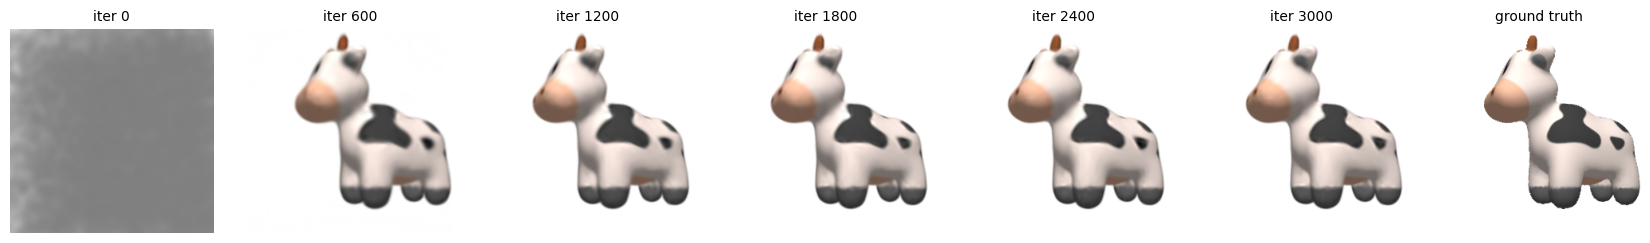

In [3]:
g1 = random_gaussian_params(N, device=device)   # uniformly in the cube [-1, 1]^3
hist1 = train_gaussians(renderers, g1, gt_train, gt_test, train_poses, test_poses, GAUSSIAN_ITERS,
                        snapshot_every=GAUSSIAN_ITERS // 5, log_every=GAUSSIAN_ITERS // 6)
snaps = hist1['snapshots']
show_images([views[0] for _, views in snaps] + [gt_test[0][0]], [f'iter {it}' for it, _ in snaps] + ['ground truth'],
            size=2.4)

### Stage 2: extract a mesh from the Gaussians

extracted mesh: 5386 vertices, 10768 triangles
Chamfer distance to the ground truth: 0.0139


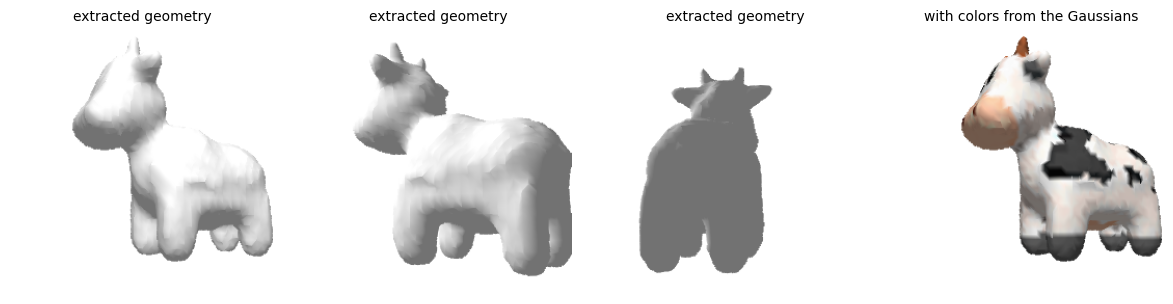

In [4]:
verts, faces = extract_mesh(gaussian_rasterizer, camera, g1, extraction_poses(device), grid=48)
print(f'extracted mesh: {verts.shape[0]} vertices, {faces.shape[0]} triangles')
print(f'Chamfer distance to the ground truth: {chamfer_distance(verts, faces, gt_mesh.verts, gt_mesh.faces):.4f}')
mesh = initial_mesh(verts, faces, colors_from_gaussians(verts, faces, g1, light))
with torch.no_grad():
    show_images([geometry(verts, faces, p) for p in test_poses[:3]] + [mesh_renderer.render(make_mesh(mesh), test_poses[0])[0][0]],
                ['extracted geometry'] * 3 + ['with colors from the Gaussians'])

### Stage 3: train the mesh

iter   250  loss 0.0343  (5.5s)
iter   500  loss 0.0229  (11.0s)
iter   750  loss 0.0181  (16.4s)
iter  1000  loss 0.0155  (21.9s)
iter  1250  loss 0.0138  (27.4s)
iter  1500  loss 0.0123  test PSNR 31.39  (32.9s)
Chamfer distance to the ground truth: 0.0090


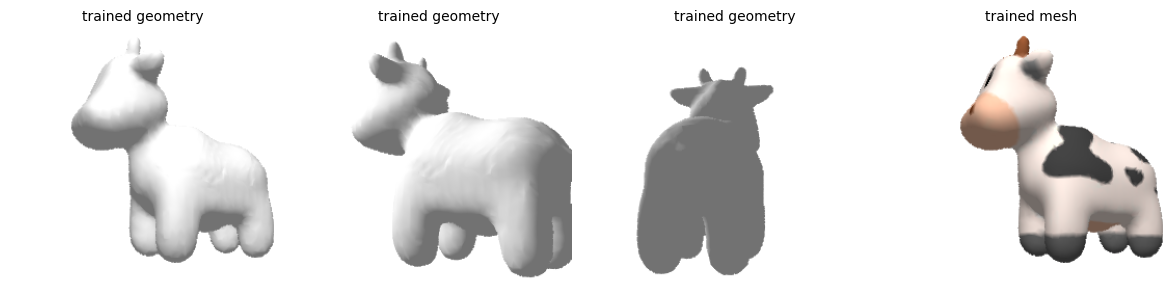

In [5]:
hist3 = train_mesh(renderers, mesh, gt_train, gt_test, train_poses, test_poses, MESH_ITERS,
                   snapshot_every=MESH_ITERS // 5, log_every=MESH_ITERS // 6)
print(f"Chamfer distance to the ground truth: {chamfer_distance(mesh_verts(mesh).detach(), faces, gt_mesh.verts, gt_mesh.faces):.4f}")
show_images([geometry(mesh_verts(mesh), faces, p) for p in test_poses[:3]] + [hist3['snapshots'][-1][1][0]],
            ['trained geometry'] * 3 + ['trained mesh'])

### Stage 4: add N / 4 Gaussians and train both

iter   250  loss 0.0133  (7.5s)
iter   500  loss 0.0114  test PSNR 32.28  (15.0s)
iter   750  loss 0.0107  (22.4s)
iter  1000  loss 0.0103  test PSNR 32.90  (30.0s)
iter  1250  loss 0.0100  (37.5s)
iter  1500  loss 0.0095  test PSNR 33.15  (45.0s)
iter  1750  loss 0.0093  (52.4s)
iter  2000  loss 0.0092  test PSNR 33.27  (60.0s)


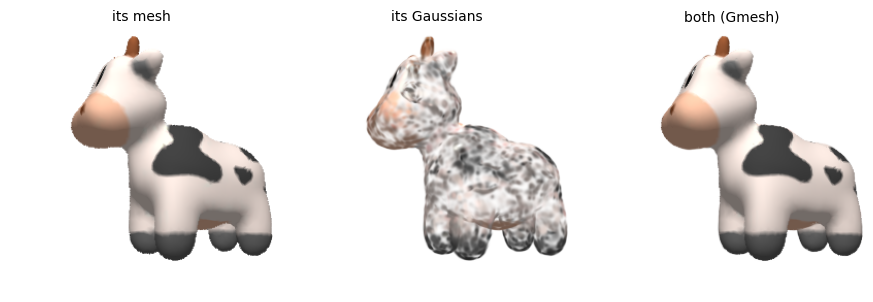

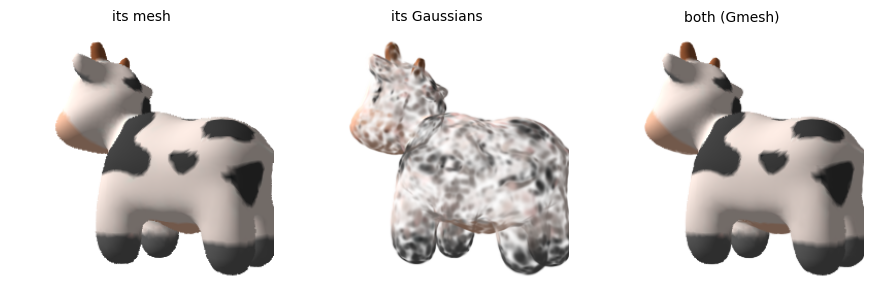

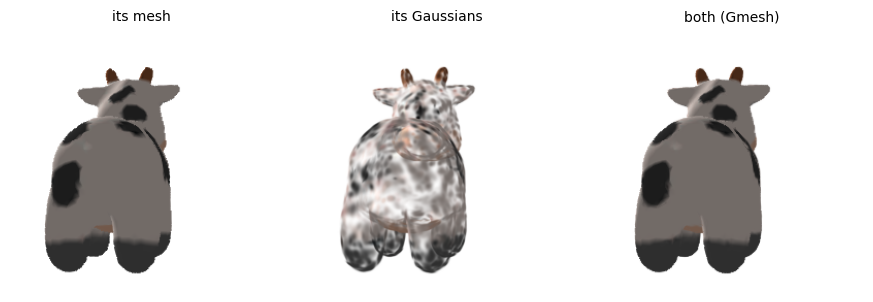

In [6]:
hist4, m_params, g4 = train_hybrid(renderers, mesh, N // 4, gt_train, gt_test, train_poses, test_poses, HYBRID_ITERS,
                                   snapshot_every=HYBRID_ITERS // 4, log_every=HYBRID_ITERS // 8)
with torch.no_grad():
    for pose in test_poses[:3]:
        ret = gmesh_renderer.render(mesh=make_mesh(mesh, m_params), gaussians=make_gaussians(g4), camera_pose=pose,
                                    return_all=True)
        show_images([ret['mesh'][0][0], ret['3dgs'][0][0], ret['blend'][0][0]], ['its mesh', 'its Gaussians', 'both (Gmesh)'])

### Baselines: more iterations for the stage 1 Gaussians, and N / 4 Gaussians alone

In [7]:
g1_more = {k: v.detach().clone() for k, v in g1.items()}
hist_more = train_gaussians(renderers, g1_more, gt_train, gt_test, train_poses, test_poses, MESH_ITERS + HYBRID_ITERS,
                            log_every=(MESH_ITERS + HYBRID_ITERS) // 4)
g_small = random_gaussian_params(N // 4, device=device, seed=1)
hist_small = train_gaussians(renderers, g_small, gt_train, gt_test, train_poses, test_poses,
                             GAUSSIAN_ITERS + MESH_ITERS + HYBRID_ITERS, log_every=GAUSSIAN_ITERS)

iter   875  loss 0.0113  (18.3s)
iter  1750  loss 0.0096  (36.5s)
iter  2625  loss 0.0087  (54.8s)
iter  3500  loss 0.0084  test PSNR 32.29  (73.1s)
iter  3000  loss 0.0406  (26.6s)
iter  6000  loss 0.0177  (52.9s)
iter  6500  loss 0.0174  test PSNR 28.94  (57.4s)


### Compare: quality and number of parameters

stage 1: 20000 Gaussians             test PSNR  30.61 dB     280000 parameters
stage 3: mesh                        test PSNR  31.39 dB      32316 parameters
stage 4: mesh + 5000 Gaussians       test PSNR  33.27 dB     102316 parameters
20000 Gaussians, trained further     test PSNR  32.29 dB     280000 parameters
5000 Gaussians alone                 test PSNR  28.94 dB      70000 parameters


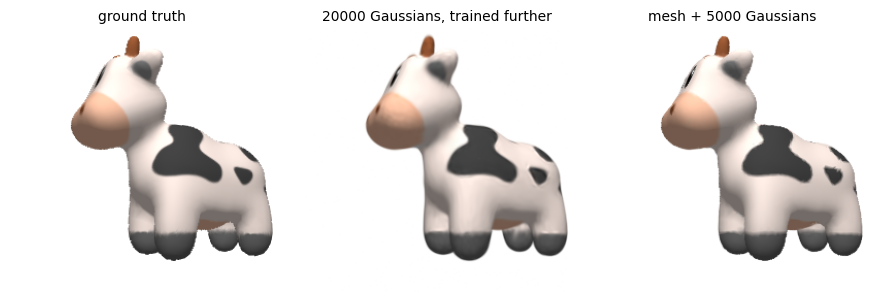

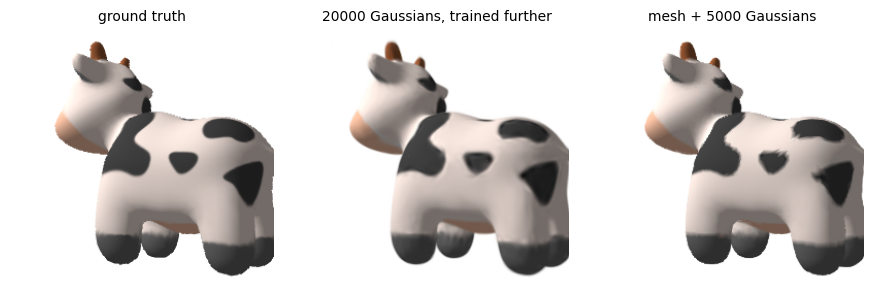

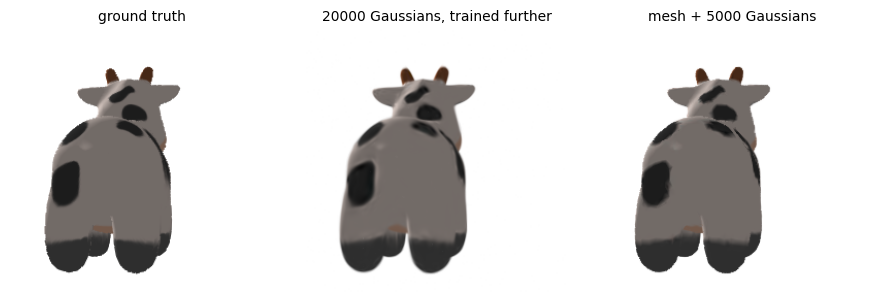

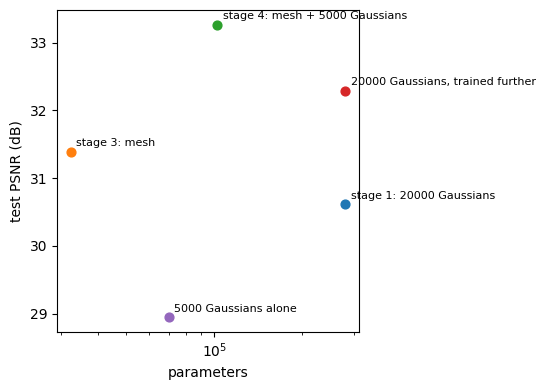

In [8]:
rows = [
    (f'stage 1: {N} Gaussians', hist1, count(g1)),
    ('stage 3: mesh', hist3, count(mesh['params'])),
    (f'stage 4: mesh + {N // 4} Gaussians', hist4, count(m_params) + count(g4)),
    (f'{N} Gaussians, trained further', hist_more, count(g1_more)),
    (f'{N // 4} Gaussians alone', hist_small, count(g_small)),
]
for name, h, p in rows:
    print(f"{name:36s} test PSNR {h['psnr'][-1]:6.2f} dB   {p:8d} parameters")

for view in range(3):
    show_images([gt_test[view][0], hist_more['snapshots'][-1][1][view], hist4['snapshots'][-1][1][view]],
                ['ground truth', f'{N} Gaussians, trained further', f'mesh + {N // 4} Gaussians'])

plt.figure(figsize=(5.5, 4))
for name, h, p in rows:
    plt.scatter(p, h['psnr'][-1], s=40)
    plt.annotate(name, (p, h['psnr'][-1]), fontsize=8, xytext=(4, 4), textcoords='offset points')
plt.xscale('log'); plt.xlabel('parameters'); plt.ylabel('test PSNR (dB)'); plt.tight_layout(); plt.show()